# 01 - Phân tích dữ liệu ViGoEmotions (Midterm, mục A)
Notebook chỉ xuất **thống kê tổng hợp** (không in/lưu văn bản gốc) để tuân thủ license của dataset.
Mọi thống kê dùng để *thiết kế* (nhóm head/mid/tail, ma trận đồng xuất hiện) chỉ tính trên **tập train**.

In [1]:
import sys, re, json, collections
sys.path.insert(0, '..')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.data import *

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
FIG = '../results/figures/'; TAB = '../results/tables/'
data = load_all()
Ytr, Yva, Yte = (label_matrix(data[s]) for s in ('train', 'val', 'test'))
all_df = pd.concat([data[s].assign(split=s) for s in data], ignore_index=True)
print({s: len(df) for s, df in data.items()}, 'tổng =', len(all_df))

C:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'train': 16531, 'val': 2066, 'test': 2067} tổng = 20664


## 1. Quy mô và bộ nhãn
28 chỉ số: 27 cảm xúc + `neutral` (index 27), theo README của dataset.

In [2]:
cnt = pd.DataFrame({'train': Ytr.sum(0), 'val': Yva.sum(0), 'test': Yte.sum(0)}, index=LABELS)
cnt['total'] = cnt.sum(1)
cnt['pct_train'] = (cnt['train'] / len(Ytr) * 100).round(2)
tiers = label_tiers(Ytr.sum(0))
cnt['tier'] = [tiers[l] for l in LABELS]
cnt = cnt.sort_values('train', ascending=False)
cnt.to_csv(TAB + 'label_distribution.csv')
print(f'Ngưỡng (định nghĩa trước, trên train): head >= {HEAD_MIN}, mid [{TAIL_MAX},{HEAD_MIN}), tail < {TAIL_MAX}')
print(cnt.tier.value_counts().to_dict())
cnt

Ngưỡng (định nghĩa trước, trên train): head >= 1000, mid [750,1000), tail < 750
{'head': 10, 'mid': 10, 'tail': 8}


C:\Users\Admin\AppData\Local\Temp\ipykernel_16224\1093322064.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  cnt['total'] = cnt.sum(1)


,train,val,test,total,pct_train,tier
amusement,2868,327,374,3569,17.35,head
sadness,2785,354,345,3484,16.85,head
annoyance,2662,331,343,3336,16.10,head
joy,1614,168,204,1986,9.76,head
anger,1589,185,189,1963,9.61,head
disappointment,1522,211,197,1930,9.21,head
disgust,1206,164,141,1511,7.30,head
love,1175,148,143,1466,7.11,head
caring,1062,131,150,1343,6.42,head
optimism,1046,122,142,1310,6.33,head


## 2. Phân bố tần suất nhãn (head / mid / tail)

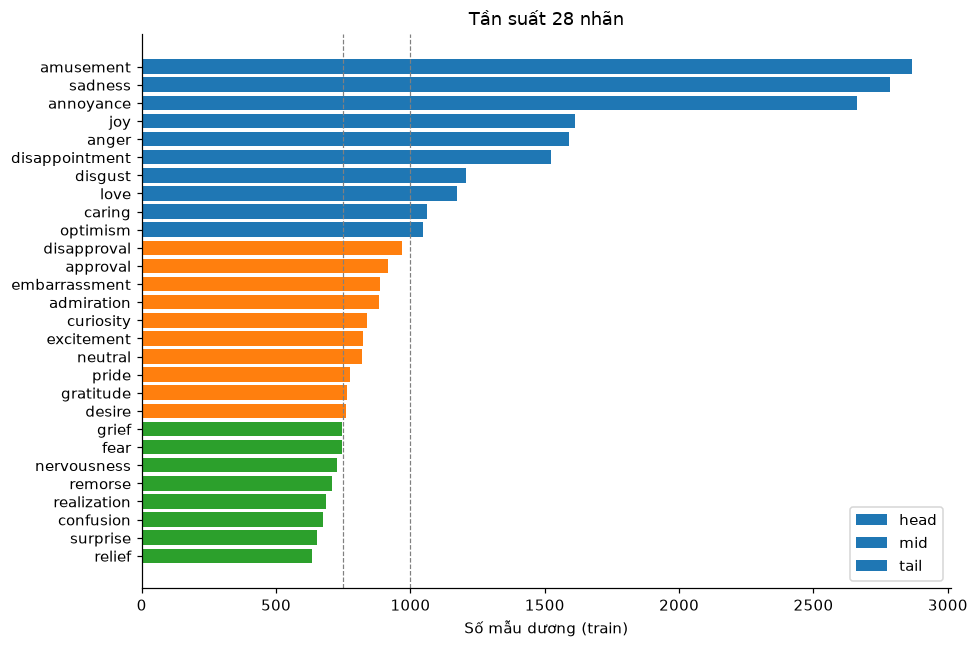

Imbalance ratio (max/min): 4.52


In [3]:
colors = {'head': '#1f77b4', 'mid': '#ff7f0e', 'tail': '#2ca02c'}
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(cnt.index[::-1], cnt['train'][::-1], color=[colors[t] for t in cnt.tier[::-1]])
ax.axvline(HEAD_MIN, ls='--', c='gray', lw=.8); ax.axvline(TAIL_MAX, ls='--', c='gray', lw=.8)
ax.set_xlabel('Số mẫu dương (train)'); ax.set_title('Tần suất 28 nhãn')
for t, c in colors.items(): ax.barh([], [], color=c, label=t)
ax.legend(); plt.tight_layout(); plt.savefig(FIG + 'label_frequency.png'); plt.show()
print('Imbalance ratio (max/min):', round(cnt.train.max() / cnt.train.min(), 2))

## 3. Label cardinality |Y|

split,train,val,test
n_labels,,,
1,5431,679,695
2,7706,944,946
3,2915,388,360
4,438,48,54
5,41,7,12


Cardinality trung bình: {'train': np.float64(1.908), 'val': np.float64(1.916), 'test': np.float64(1.908)}
Label density (card/28): 0.068


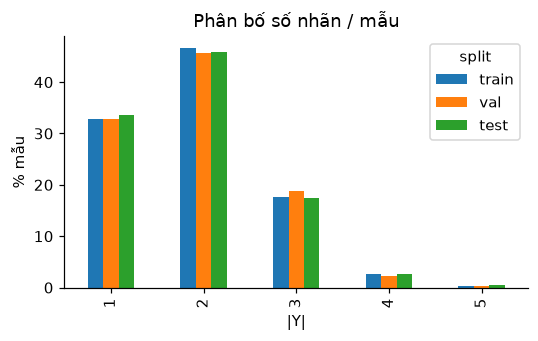

In [4]:
card = all_df.groupby('split').n_labels.value_counts().unstack(0).fillna(0).astype(int)
card = card[['train', 'val', 'test']]
card.to_csv(TAB + 'cardinality.csv')
display(card)
print('Cardinality trung bình:', {s: round(data[s].n_labels.mean(), 3) for s in data})
print('Label density (card/28):', round(data['train'].n_labels.mean() / NUM_LABELS, 3))
fig, ax = plt.subplots(figsize=(5, 3.2))
(card / card.sum() * 100).plot.bar(ax=ax); ax.set_ylabel('% mẫu'); ax.set_xlabel('|Y|'); ax.set_title('Phân bố số nhãn / mẫu')
plt.tight_layout(); plt.savefig(FIG + 'cardinality.png'); plt.show()

## 4. Đồng xuất hiện và tương quan nhãn (chỉ train)

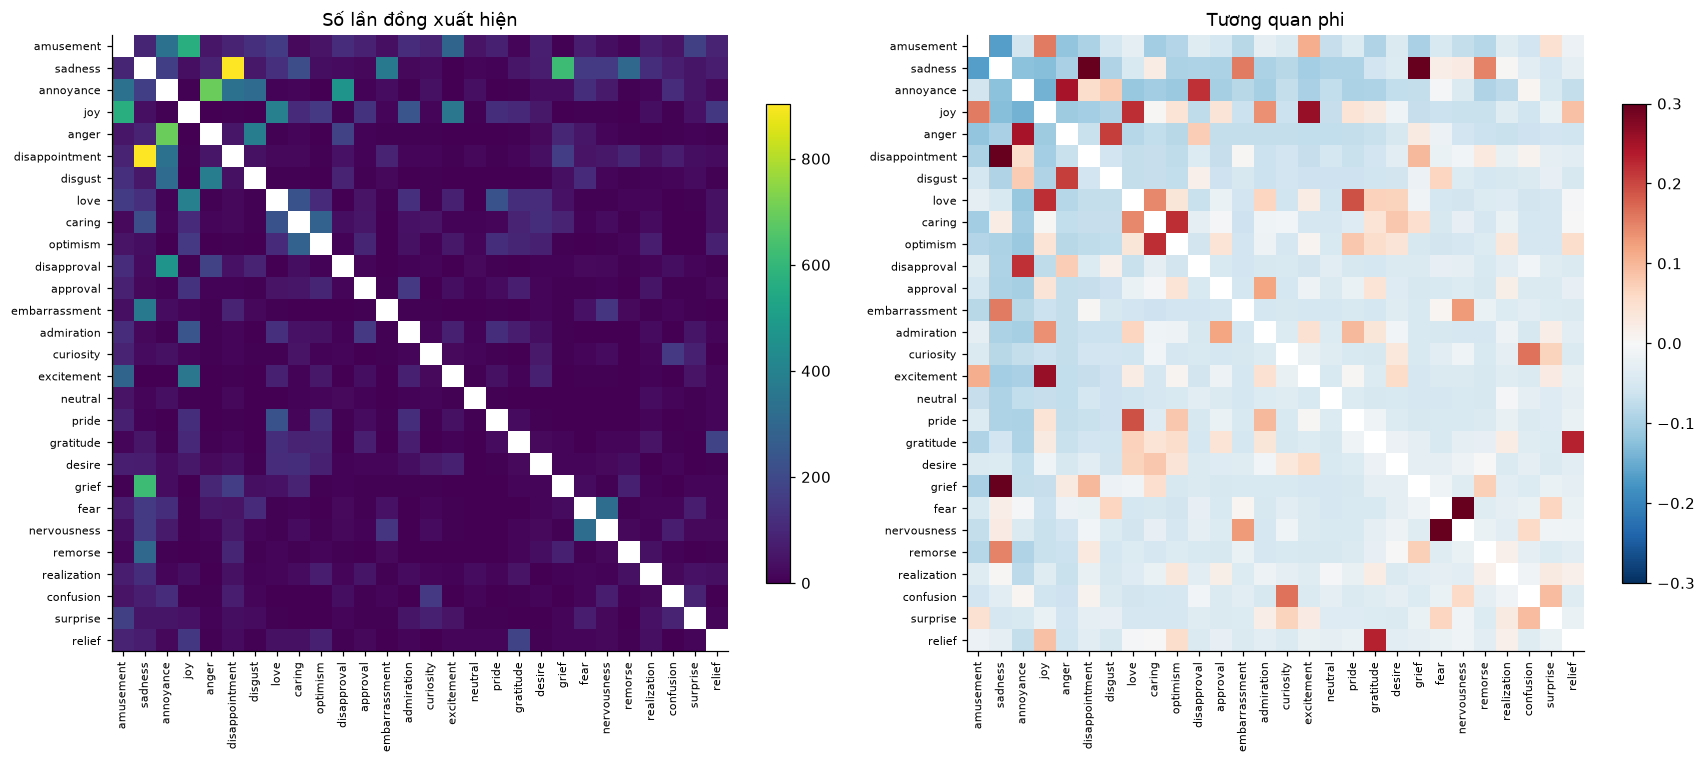

Top 15 cặp theo số lần đồng xuất hiện


,a,b,count,phi,jaccard
350,disappointment,sadness,904,0.362004,0.266
372,anger,annoyance,699,0.247417,0.197
357,sadness,grief,620,0.384494,0.213
1,amusement,joy,568,0.154993,0.145
375,annoyance,disapproval,469,0.219265,0.148
53,joy,love,395,0.222300,0.165
368,disgust,anger,379,0.207606,0.157
343,embarrassment,sadness,366,0.155736,0.111
27,excitement,joy,359,0.260854,0.173
24,amusement,annoyance,336,-0.054691,0.065


Top 10 cặp tương quan dương mạnh nhất


,a,b,count,phi,jaccard
312,fear,nervousness,322,0.410993,0.280
357,sadness,grief,620,0.384494,0.213
350,disappointment,sadness,904,0.362004,0.266
27,excitement,joy,359,0.260854,0.173
372,anger,annoyance,699,0.247417,0.197
207,gratitude,relief,184,0.231647,0.151
53,joy,love,395,0.222300,0.165
125,optimism,caring,286,0.221736,0.157
375,annoyance,disapproval,469,0.219265,0.148
368,disgust,anger,379,0.207606,0.157


Top 10 cặp tương quan âm mạnh nhất


,a,b,count,phi,jaccard
20,amusement,sadness,95,-0.165678,0.017
75,joy,annoyance,5,-0.141337,0.001
71,joy,sadness,36,-0.128457,0.008
360,sadness,annoyance,167,-0.123767,0.032
23,amusement,anger,56,-0.119058,0.013
99,love,annoyance,10,-0.114784,0.003
144,optimism,annoyance,3,-0.111837,0.001
74,joy,anger,0,-0.107268,0.000
165,caring,annoyance,14,-0.105395,0.004
5,amusement,caring,24,-0.104409,0.006


In [5]:
co = Ytr.T.astype(int) @ Ytr.astype(int)           # co[i,j] = số mẫu có cả i và j
corr = np.corrcoef(Ytr.T.astype(float))             # Pearson (= phi) giữa các nhãn
order = np.argsort(-Ytr.sum(0))
names = [LABELS[i] for i in order]
eye = np.eye(NUM_LABELS) > 0
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, M, t, kw in [(axes[0], np.where(eye, np.nan, co)[np.ix_(order, order)], 'Số lần đồng xuất hiện', {}),
                     (axes[1], np.where(eye, np.nan, corr)[np.ix_(order, order)], 'Tương quan phi', dict(vmin=-.3, vmax=.3, cmap='RdBu_r'))]:
    im = ax.imshow(M, **kw); ax.set_xticks(range(NUM_LABELS)); ax.set_yticks(range(NUM_LABELS))
    ax.set_xticklabels(names, rotation=90, fontsize=7); ax.set_yticklabels(names, fontsize=7); ax.set_title(t); plt.colorbar(im, ax=ax, shrink=.7)
plt.tight_layout(); plt.savefig(FIG + 'cooccurrence_correlation.png'); plt.show()

iu = np.triu_indices(NUM_LABELS, 1)
pairs = pd.DataFrame({'a': [LABELS[i] for i in iu[0]], 'b': [LABELS[j] for j in iu[1]], 'count': co[iu], 'phi': corr[iu]})
n = Ytr.sum(0); pairs['jaccard'] = (pairs['count'] / (n[iu[0]] + n[iu[1]] - pairs['count'])).round(3)
pairs.sort_values('count', ascending=False).to_csv(TAB + 'label_pairs.csv', index=False)
print('Top 15 cặp theo số lần đồng xuất hiện'); display(pairs.sort_values('count', ascending=False).head(15))
print('Top 10 cặp tương quan dương mạnh nhất'); display(pairs.sort_values('phi', ascending=False).head(10))
print('Top 10 cặp tương quan âm mạnh nhất'); display(pairs.sort_values('phi').head(10))

In [6]:
# neutral có đi cùng nhãn khác không?
neu = LABELS.index('neutral'); m = Ytr[:, neu] == 1
print('Mẫu neutral:', m.sum(), '| neutral đứng một mình:', int((Ytr[m].sum(1) == 1).sum()))

Mẫu neutral: 821 | neutral đứng một mình: 570


## 5. Độ dài văn bản (token tách theo khoảng trắng và ký tự)

,n_tok,n_chr
count,20664.0,20664.0
mean,16.1,66.8
std,15.9,67.2
min,1.0,1.0
50%,11.0,47.0
90%,32.0,133.0
95%,44.0,187.0
99%,86.0,360.7
max,214.0,906.0


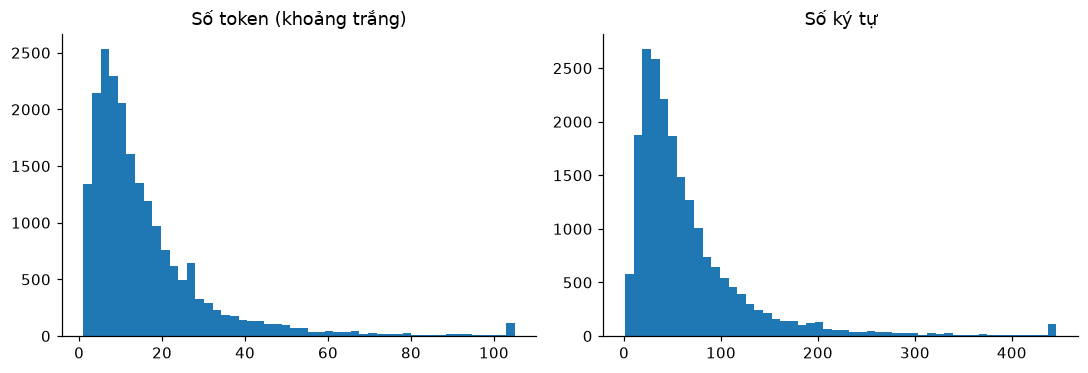

Số mẫu có > 64 token: 423 | > 128 token: 37


In [7]:
all_df['n_tok'] = all_df.text.str.split().str.len()
all_df['n_chr'] = all_df.text.str.len()
desc = all_df.groupby('split')[['n_tok', 'n_chr']].describe(percentiles=[.5, .9, .95, .99]).T
desc.to_csv(TAB + 'text_length.csv'); display(all_df[['n_tok', 'n_chr']].describe(percentiles=[.5, .9, .95, .99]).round(1))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col, t in [(axes[0], 'n_tok', 'Số token (khoảng trắng)'), (axes[1], 'n_chr', 'Số ký tự')]:
    ax.hist(all_df[col].clip(upper=all_df[col].quantile(.995)), bins=50); ax.set_title(t)
plt.tight_layout(); plt.savefig(FIG + 'text_length.png'); plt.show()
print('Số mẫu có > 64 token:', int((all_df.n_tok > 64).sum()), '| > 128 token:', int((all_df.n_tok > 128).sum()))

## 6. Đặc trưng văn bản mạng xã hội
Chỉ báo bằng heuristic regex (xấp xỉ): emoji, kéo dài ký tự, viết tắt/teencode phổ biến, không dấu, chữ hoa, dấu câu lặp.

In [8]:
EMOJI = re.compile('[\U0001F300-\U0001FAFF\u2600-\u27BF\U0001F000-\U0001F2FF\u2B50\u2764]')
ELONG = re.compile(r'(.)\1{2,}')                     # "quááááá", "hahahaha" -> ký tự lặp >= 3
REPPUNC = re.compile(r'[!?.]{2,}')
VN_DIAC = re.compile('[àáảãạăằắẳẵặâầấẩẫậèéẻẽẹêềếểễệìíỉĩịòóỏõọôồốổỗộơờớởỡợùúủũụưừứửữựỳýỷỹỵđ]', re.I)
TEEN = {'ko', 'k', 'kh', 'hok', 'hong', 'dc', 'đc', 'dk', 'vs', 'vl', 'vcl', 'cx', 'cg', 'bt', 'bik', 'biet', 'wa', 'r', 'rùi', 'ntn', 'mn', 'ae',
        'ok', 'oke', 'j', 'z', 'zậy', 'trc', 'sg', 'nc', 'nhìu', 'nhiu', 'thik', 'iu', 'cmt', 'sv', 'hnay', 'mik', 'mìk'}
def feats(t):
    toks = t.lower().split()
    return pd.Series({'emoji': bool(EMOJI.search(t)), 'n_emoji': len(EMOJI.findall(t)), 'elong': bool(ELONG.search(t)),
                      'repunc': bool(REPPUNC.search(t)), 'upper': sum(c.isupper() for c in t) / max(1, sum(c.isalpha() for c in t)) > .5,
                      'no_diac': (len(t) >= 15) and not VN_DIAC.search(t), 'teen_tok': sum(w in TEEN for w in toks)})
F = all_df.text.apply(feats)
all_df = pd.concat([all_df, F], axis=1)
all_df['teencode'] = all_df.teen_tok > 0
rate = (all_df.groupby('split')[['emoji', 'elong', 'repunc', 'upper', 'no_diac', 'teencode']].mean() * 100).round(2)
rate.to_csv(TAB + 'informal_features.csv'); print('% mẫu có đặc trưng'); display(rate)
print('Emoji trung bình / mẫu có emoji:', round(all_df.loc[all_df.emoji, 'n_emoji'].mean(), 2))

% mẫu có đặc trưng


,emoji,elong,repunc,upper,no_diac,teencode
split,,,,,,
test,25.93,12.82,7.40,0.29,0.82,16.79
train,24.90,14.29,7.54,0.30,0.89,16.36
val,24.64,13.75,7.70,0.19,0.63,17.62


Emoji trung bình / mẫu có emoji: 2.06


In [9]:
# Tần suất đặc trưng theo nhãn (train): nhãn nào hay đi kèm emoji / teencode?
tr = all_df[all_df.split == 'train'].reset_index(drop=True)
rows = []
for i, l in enumerate(LABELS):
    sel = tr[Ytr[:, i] == 1]
    rows.append({'label': l, 'n': len(sel), '%emoji': sel.emoji.mean() * 100, '%teencode': sel.teencode.mean() * 100, '%elong': sel.elong.mean() * 100, 'tok_mean': sel.n_tok.mean()})
bylab = pd.DataFrame(rows).set_index('label').round(1).sort_values('%emoji', ascending=False)
bylab.to_csv(TAB + 'informal_by_label.csv'); bylab.head(10)

,n,%emoji,%teencode,%elong,tok_mean
label,,,,,
love,1175,48.9,8.2,18.1,13.2
pride,774,44.7,16.3,12.1,15.0
amusement,2868,40.8,12.1,30.5,14.2
relief,635,38.7,20.5,16.5,22.5
embarrassment,885,38.4,33.0,13.0,15.5
joy,1614,37.1,8.7,21.7,13.4
grief,747,35.2,19.5,15.8,18.5
remorse,707,33.5,25.7,11.9,22.8
sadness,2785,31.7,19.8,13.9,18.2


In [10]:
# Từ viết tắt hay gặp nhất - chỉ xuất tần suất, không xuất câu gốc
tok_counter = collections.Counter(w for t in tr.text for w in t.lower().split())
pd.Series({w: tok_counter[w] for w in TEEN if tok_counter[w] > 0}).sort_values(ascending=False).head(20)

ko      1222
k        734
đc       455
r        180
vs       170
dc       162
j        152
cx       137
mik      134
kh       109
bt        78
mn        69
trc       65
cmt       65
z         56
vl        44
nc        42
nhìu      41
ok        40
ntn       38
dtype: int64

## 7. Giao thức chia train / validation / test
Dataset cung cấp sẵn split chính thức 80/10/10. Ta **dùng nguyên split này** (cũng là split của paper gốc, nên so sánh được). Kiểm tra: không trùng id, phân bố nhãn gần như đồng đều giữa các split. Lưu file chỉ số vào `splits/`; threshold chỉ được tune trên val, co-occurrence chỉ tính trên train.

In [11]:
ids = {s: set(data[s].id) for s in data}
assert not (ids['train'] & ids['val']) and not (ids['train'] & ids['test']) and not (ids['val'] & ids['test'])
for s in data: data[s][['id']].rename(columns={'id': 'sample_id'}).to_csv(f'../splits/{s}.csv', index=False)
prev = pd.DataFrame({s: label_matrix(data[s]).mean(0) * 100 for s in data}, index=LABELS)
prev['max_diff'] = prev[['train', 'val', 'test']].max(1) - prev[['train', 'val', 'test']].min(1)
print('Chênh lệch tỷ lệ nhãn lớn nhất giữa các split (điểm %):', round(prev.max_diff.max(), 2), '| nhãn:', prev.max_diff.idxmax())
print('Số mẫu dương ít nhất trong test:', int(Yte.sum(0).min()), '(', LABELS[int(Yte.sum(0).argmin())], ')')
json.dump({'tiers': tiers, 'head_min': HEAD_MIN, 'tail_max': TAIL_MAX, 'labels': LABELS, 'seed': SEED}, open('../splits/label_tiers.json', 'w'), indent=1)
prev.round(2)

Chênh lệch tỷ lệ nhãn lớn nhất giữa các split (điểm %): 2.27 | nhãn: amusement
Số mẫu dương ít nhất trong test: 60 ( relief )


C:\Users\Admin\AppData\Local\Temp\ipykernel_16224\3756395664.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  prev['max_diff'] = prev[['train', 'val', 'test']].max(1) - prev[['train', 'val', 'test']].min(1)
C:\Users\Admin\AppData\Local\Temp\ipykernel_16224\3756395664.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of min will be keyword-only.
  prev['max_diff'] = prev[['train', 'val', 'test']].max(1) - prev[['train', 'val', 'test']].min(1)


,train,val,test,max_diff
amusement,17.35,15.83,18.09,2.27
excitement,4.98,4.40,4.74,0.58
joy,9.76,8.13,9.87,1.74
love,7.11,7.16,6.92,0.25
desire,4.61,4.94,3.87,1.07
optimism,6.33,5.91,6.87,0.96
caring,6.42,6.34,7.26,0.92
pride,4.68,4.21,4.16,0.52
admiration,5.34,5.18,4.89,0.46
gratitude,4.63,4.65,5.22,0.60
